In [1]:
!pip install -q kaggle

In [50]:
!pip install keras

In [51]:
!pip install tensorflow

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [ ]:
from google.colab import files
files.upload()  # Select your downloaded kaggle.json file here

In [4]:
import os

# Create data directory if it doesn't exist
os.makedirs("data", exist_ok=True)

# Unzip the downloaded file
!unzip -q epileptic-seizure-recognition.zip -d data/

print("Dataset extracted successfully into the 'data/' folder!")

replace data/Epileptic Seizure Recognition.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
Dataset extracted successfully into the 'data/' folder!


In [5]:
import pandas as pd

# Load the dataset CSV (verify the exact filename inside the data folder)
# Usually it extracts as 'Epileptic Seizure Recognition.csv' or 'data.csv'
file_path = "data/Epileptic Seizure Recognition.csv" # Adjust if your unzipped name differs
df = pd.read_csv(file_path)

In [7]:
print("Dataset Shape:", df.shape)


Dataset Shape: (11500, 180)


In [8]:
print(df.head(3))

      Unnamed   X1   X2   X3   X4   X5   X6   X7   X8   X9  ...  X170  X171  \
0  X21.V1.791  135  190  229  223  192  125   55   -9  -33  ...   -17   -15   
1  X15.V1.924  386  382  356  331  320  315  307  272  244  ...   164   150   
2     X8.V1.1  -32  -39  -47  -37  -32  -36  -57  -73  -85  ...    57    64   

   X172  X173  X174  X175  X176  X177  X178  y  
0   -31   -77  -103  -127  -116   -83   -51  4  
1   146   152   157   156   154   143   129  1  
2    48    19   -12   -30   -35   -35   -36  5  

[3 rows x 180 columns]


In [9]:
df.columns

Index(['Unnamed', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9',
       ...
       'X170', 'X171', 'X172', 'X173', 'X174', 'X175', 'X176', 'X177', 'X178',
       'y'],
      dtype='object', length=180)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11500 entries, 0 to 11499
Columns: 180 entries, Unnamed to y
dtypes: int64(179), object(1)
memory usage: 15.8+ MB


In [11]:
df.describe()

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X170,X171,X172,X173,X174,X175,X176,X177,X178,y
count,11500.000000,11500.000000,11500.000000,11500.000000,11500.000000,11500.000000,11500.000000,11500.00000,11500.00000,11500.000000,...,11500.000000,11500.000000,11500.000000,11500.000000,11500.000000,11500.000000,11500.000000,11500.000000,11500.000000,11500.000000
mean,-11.581391,-10.911565,-10.187130,-9.143043,-8.009739,-7.003478,-6.502087,-6.68713,-6.55800,-6.168435,...,-10.145739,-11.630348,-12.943478,-13.668870,-13.363304,-13.045043,-12.705130,-12.426000,-12.195652,3.000000
std,165.626284,166.059609,163.524317,161.269041,160.998007,161.328725,161.467837,162.11912,162.03336,160.436352,...,164.652883,166.149790,168.554058,168.556486,167.257290,164.241019,162.895832,162.886311,164.852015,1.414275
min,-1839.000000,-1838.000000,-1835.000000,-1845.000000,-1791.000000,-1757.000000,-1832.000000,-1778.00000,-1840.00000,-1867.000000,...,-1867.000000,-1865.000000,-1642.000000,-1723.000000,-1866.000000,-1863.000000,-1781.000000,-1727.000000,-1829.000000,1.000000
25%,-54.000000,-55.000000,-54.000000,-54.000000,-54.000000,-54.000000,-54.000000,-55.00000,-55.00000,-54.000000,...,-55.000000,-56.000000,-56.000000,-56.000000,-55.000000,-56.000000,-55.000000,-55.000000,-55.000000,2.000000
50%,-8.000000,-8.000000,-7.000000,-8.000000,-8.000000,-8.000000,-8.000000,-8.00000,-7.00000,-7.000000,...,-9.000000,-10.000000,-10.000000,-10.000000,-10.000000,-9.000000,-9.000000,-9.000000,-9.000000,3.000000
75%,34.000000,35.000000,36.000000,36.000000,35.000000,36.000000,35.000000,36.00000,36.00000,35.250000,...,34.000000,34.000000,33.000000,33.000000,34.000000,34.000000,34.000000,34.000000,34.000000,4.000000
max,1726.000000,1713.000000,1697.000000,1612.000000,1518.000000,1816.000000,2047.000000,2047.00000,2047.00000,2047.000000,...,1777.000000,1472.000000,1319.000000,1436.000000,1733.000000,1958.000000,2047.000000,2047.000000,1915.000000,5.000000


In [12]:
# Check the distribution of the target labels (last column)
print(df.iloc[:, -1].value_counts())

y
4    2300
1    2300
5    2300
2    2300
3    2300
Name: count, dtype: int64


In [17]:
df.isnull().sum()

,0
Unnamed,0
X1,0
X2,0
X3,0
X4,0
...,...
X175,0
X176,0
X177,0
X178,0


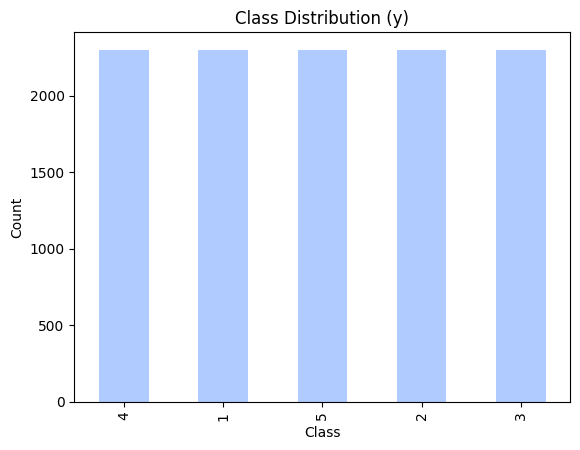

In [32]:
# Use a valid matplotlib color (e.g., 'skyblue') to fix the ValueError
df['y'].value_counts().plot(kind='bar', color='#AFCBFF')  # pastel blue

plt.title("Class Distribution (y)")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

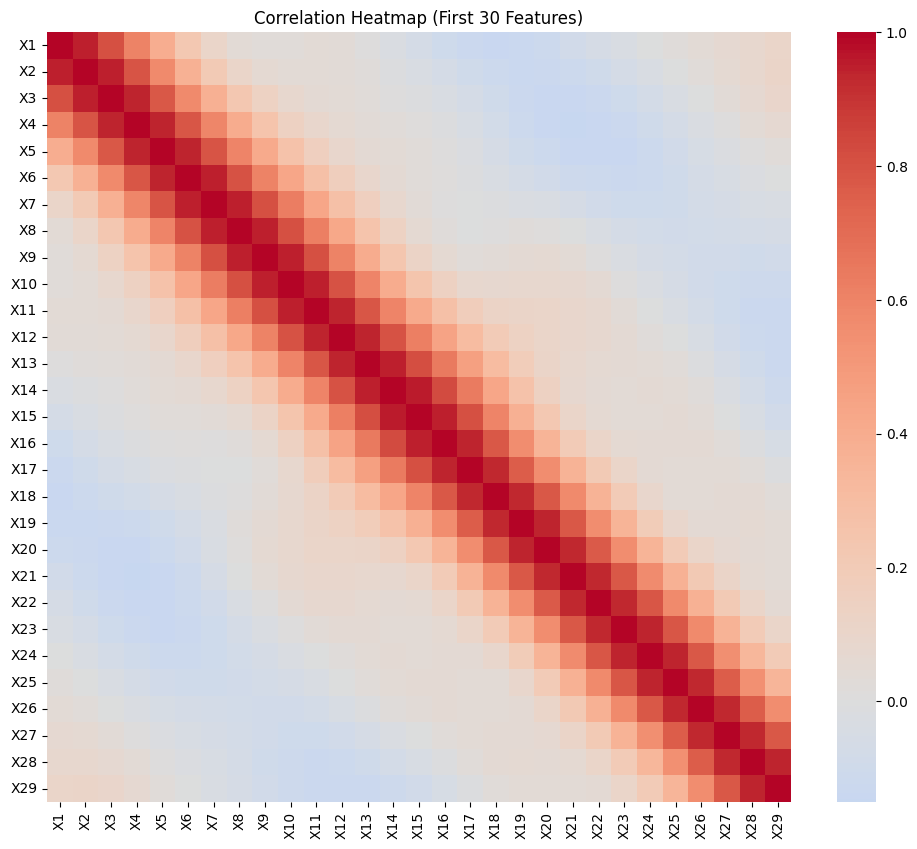

In [20]:
subset = df.iloc[:, :30]

plt.figure(figsize=(12,10))
sns.heatmap(
    subset.corr(numeric_only=True),
    cmap='coolwarm',
    center=0
)
plt.title("Correlation Heatmap (First 30 Features)")
plt.show()

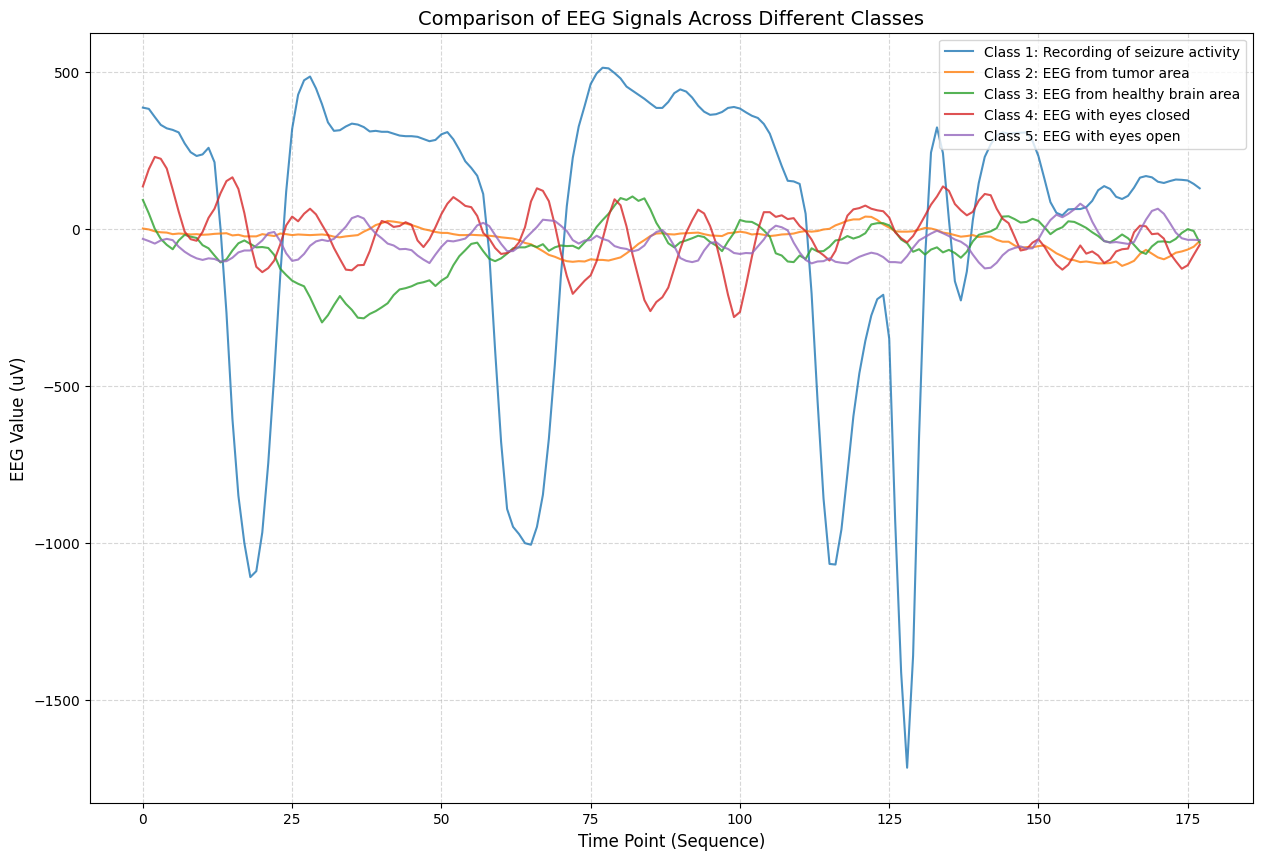

In [21]:
plt.figure(figsize=(15, 10))

# Map of class labels to their actual meanings in the dataset
class_labels = {
    1: "Class 1: Recording of seizure activity",
    2: "Class 2: EEG from tumor area",
    3: "Class 3: EEG from healthy brain area",
    4: "Class 4: EEG with eyes closed",
    5: "Class 5: EEG with eyes open"
}

# Plot a representative sample for each class
for label in sorted(df['y'].unique()):
    # Get the first sample belonging to this class
    sample = df[df['y'] == label].iloc[0]
    # Extract only the EEG signal values (columns X1 to X178)
    signal = sample.iloc[1:179].values.astype(float)

    plt.plot(signal, label=class_labels[label], alpha=0.8)

plt.title("Comparison of EEG Signals Across Different Classes", fontsize=14)
plt.xlabel("Time Point (Sequence)", fontsize=12)
plt.ylabel("EEG Value (uV)", fontsize=12)
plt.legend(loc="upper right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

array([[<Axes: title={'center': 'X1'}>, <Axes: title={'center': 'X2'}>,
        <Axes: title={'center': 'X3'}>],
       [<Axes: title={'center': 'X4'}>, <Axes: title={'center': 'X5'}>,
        <Axes: title={'center': 'X6'}>],
       [<Axes: title={'center': 'X7'}>, <Axes: title={'center': 'X8'}>,
        <Axes: title={'center': 'X9'}>]], dtype=object)

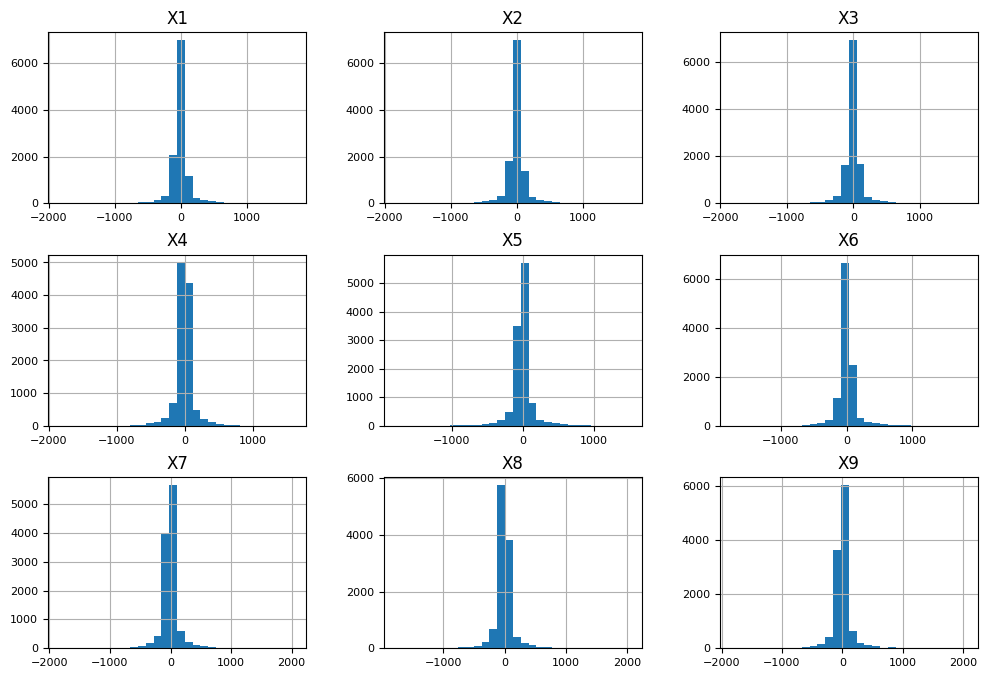

In [26]:
sample_features = df.columns[:10]

df[sample_features].hist(
    figsize=(12,8),
    bins=30,
    xlabelsize=8,
    ylabelsize=8

)

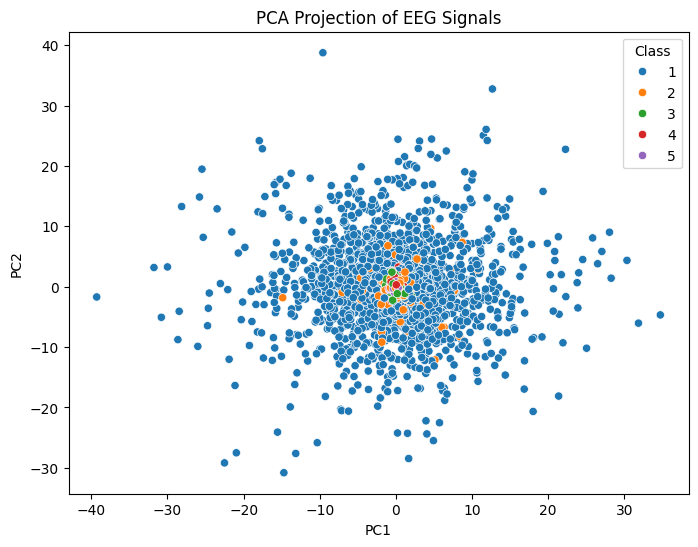

In [27]:
X = df.drop(columns=[target_col], errors='ignore')

# Remove unnamed column if exists
X = X.loc[:, ~X.columns.str.contains('unnamed', case=False)]

y = df[target_col]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    'PC1': X_pca[:,0],
    'PC2': X_pca[:,1],
    'Class': y
})

plt.figure(figsize=(8,6))
sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Class',
    palette='tab10'
)

plt.title("PCA Projection of EEG Signals")
plt.show()

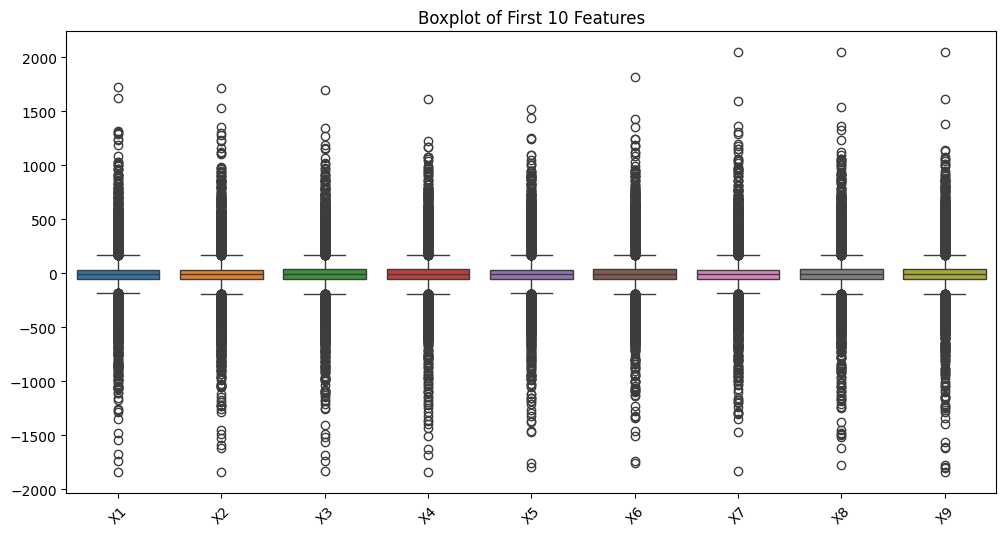

In [33]:
plt.figure(figsize=(12,6))

sns.boxplot(
    data=df[df.columns[:10]]
)

plt.xticks(rotation=45)
plt.title("Boxplot of First 10 Features")
plt.show()

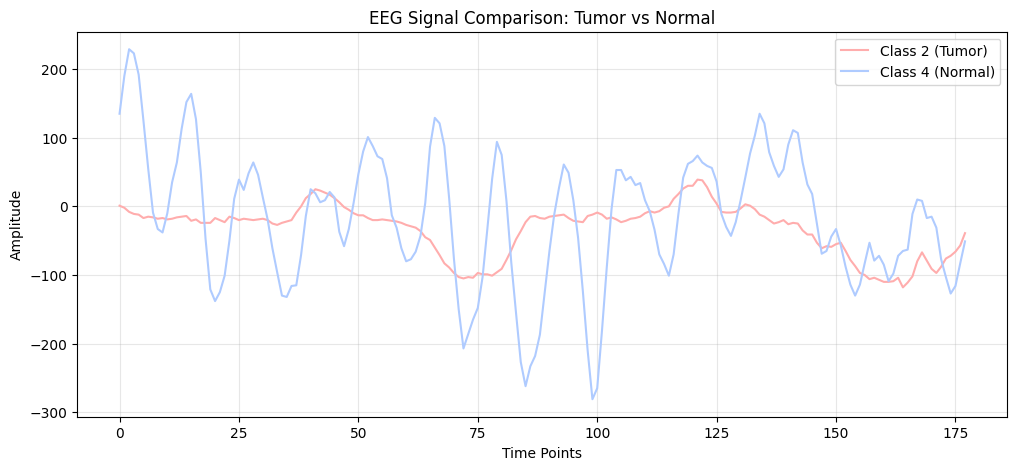

In [35]:
# Select the first matching row for each class and convert to a numpy array
tumor_sample = X[y == 2].iloc[0].values   # Class 2 (Tumor)
normal_sample = X[y == 4].iloc[0].values  # Class 4 (Normal)

plt.figure(figsize=(12, 5))

# Plot the EEG signal (up to 178 available sequence points)
plt.plot(tumor_sample[:178], color='#FFADAD', label='Class 2 (Tumor)')
plt.plot(normal_sample[:178], color='#AFCBFF', label='Class 4 (Normal)')

plt.title('EEG Signal Comparison: Tumor vs Normal')
plt.xlabel('Time Points')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

### 1. Average EEG Waveforms with Standard Deviation Bounds
Let's visualize the average signal trend for each category along with the shaded standard deviation area to see the overall structural differences between classes.

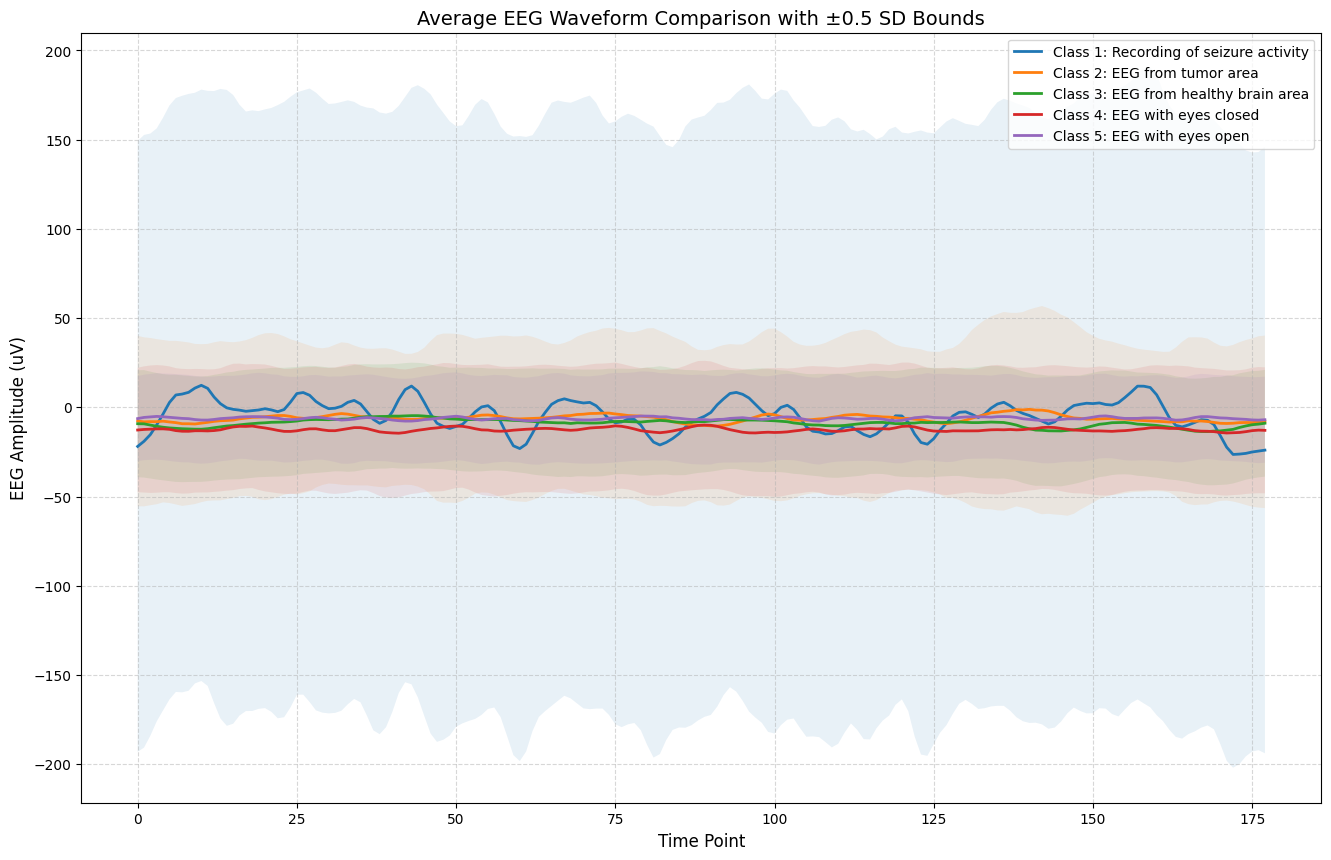

In [36]:
plt.figure(figsize=(16, 10))

# Loop through each unique class to plot mean and standard deviation bounds
for label in sorted(df['y'].unique()):
    # Get all signals for the current class (excluding Unnamed and y)
    class_signals = X[y == label].values.astype(float)

    mean_signal = class_signals.mean(axis=0)
    std_signal = class_signals.std(axis=0)

    plt.plot(mean_signal, label=class_labels[label], lw=2)
    plt.fill_between(range(len(mean_signal)),
                     mean_signal - 0.5 * std_signal,
                     mean_signal + 0.5 * std_signal,
                     alpha=0.1)

plt.title("Average EEG Waveform Comparison with ±0.5 SD Bounds", fontsize=14)
plt.xlabel("Time Point", fontsize=12)
plt.ylabel("EEG Amplitude (uV)", fontsize=12)
plt.legend(loc="upper right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 2. Distribution of Signal Variance (Signal Energy) per Class
Seizure signals (Class 1) are known to fluctuate dramatically compared to other states. We can calculate the standard deviation for each EEG recording sample and compare their distributions across the classes using a boxplot.

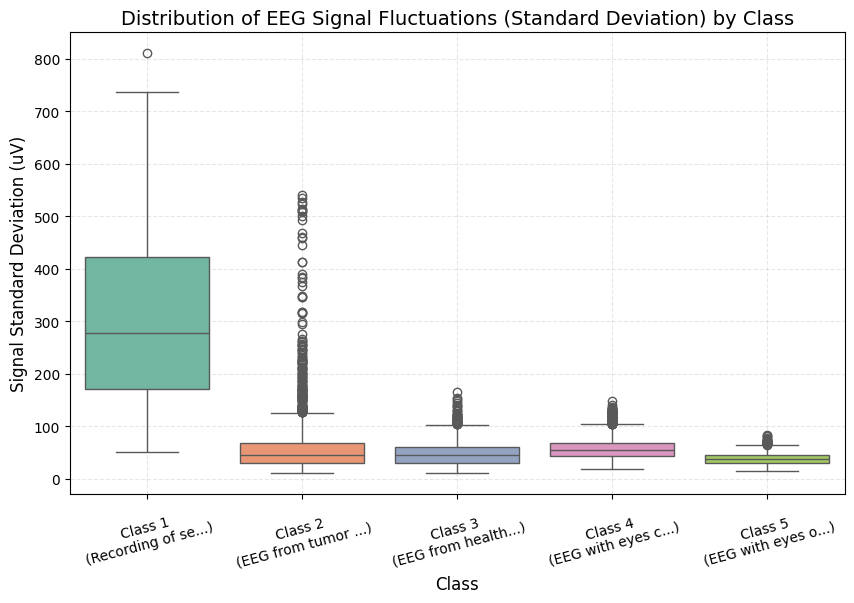

In [37]:
# Calculate standard deviation across the columns (X1 to X178) for each row
df_variance = df.copy()
df_variance['signal_std'] = X.std(axis=1)

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_variance,
    x='y',
    y='signal_std',
    palette='Set2',
    hue='y',
    legend=False
)

# Map x-ticks to easier names
plt.xticks(ticks=range(5), labels=[f"Class {i}\n({class_labels[i].split(': ')[1][:15]}...)" for i in sorted(class_labels.keys())], rotation=15)
plt.title("Distribution of EEG Signal Fluctuations (Standard Deviation) by Class", fontsize=14)
plt.xlabel("Class", fontsize=12)
plt.ylabel("Signal Standard Deviation (uV)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

In [48]:
def load_and_preprocess_neurosense_data(csv_path):
    # 1. Load dataset
    df = pd.read_csv(csv_path)

    # 2. Map classes for Binary Classification (Tumor vs. Normal)
    # Class 2 (tumor region) & Class 3 (tumor patient healthy area) -> Label 1 (Tumor/Anomaly Risk)
    # Class 4 & Class 5 (healthy control subjects) -> Label 0 (Normal)
    # We will drop Classes 1 (seizures) for this specific tumor-focused task, or keep them separate.
    df = df[df.iloc[:, -1].isin([2, 3, 4, 5])].copy()

    # Create binary target: 1 if class is 2 or 3, else 0 (for classes 4 or 5)
    df['binary_label'] = df.iloc[:, -1].apply(lambda x: 1 if x in [2, 3] else 0)

    # 3. Split Features (X) and Labels (y)
    # Columns 1 to 178 are the EEG time-series voltage points
    X = df.iloc[:, 1:179].values
    y = df['binary_label'].values

    # 4. Normalize EEG signals (Crucial for neural networks to handle scale/noise)
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # 5. Reshape for 1D-CNN -> Shape: (samples, timesteps, features)
    X_reshaped = np.expand_dims(X_scaled, axis=2)

    # 6. Train-Test Split (80% training, 20% validation)
    X_train, X_val, y_train, y_val = train_test_split(
        X_reshaped, y, test_size=0.2, random_state=42, stratify=y
    )

    print(f"Training Data Shape: {X_train.shape}")
    print(f"Validation Data Shape: {X_val.shape}")
    print(f"Class Distribution in y_train: {np.bincount(y_train)}")

    return X_train, X_val, y_train, y_val

# Execute the loader
X_train, X_val, y_train, y_val = load_and_preprocess_neurosense_data("data/Epileptic Seizure Recognition.csv")

Training Data Shape: (7360, 178, 1)
Validation Data Shape: (1840, 178, 1)
Class Distribution in y_train: [3680 3680]


In [52]:
import tensorflow as tf
from tensorflow.keras import layers, models
import os

In [53]:
def build_neurosense_1d_cnn(input_shape=(178, 1)):
    """
    Builds a 1D Convolutional Neural Network tailored for NeuroSense EEG time-series analysis.
    """
    model = models.Sequential([
        # Block 1: Feature Extraction
        layers.Input(shape=input_shape),
        layers.Conv1D(64, kernel_size=5, activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),
        layers.Dropout(0.3),

        # Block 2: Deep Pattern Recognition
        layers.Conv1D(128, kernel_size=3, activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),
        layers.Dropout(0.3),

        # Block 3: Higher-Level Representations
        layers.Conv1D(256, kernel_size=3, activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.GlobalAveragePooling1D(),

        # Classification Head
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(1, activation='sigmoid')  # Binary output: Normal (0) vs. Tumor/Anomaly Risk (1)
    ])

    return model

In [54]:
# 1. Create directory for model checkpoints
os.makedirs("models", exist_ok=True)

# 2. Instantiate and compile model
model = build_neurosense_1d_cnn()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 178, 64)        │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 178, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 89, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 89, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 89, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 89, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 44, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 44, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 44, 256)        │        98,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 44, 256)        │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 158,465 (619.00 KB)

 Trainable params: 157,569 (615.50 KB)

 Non-trainable params: 896 (3.50 KB)

In [55]:
# 3. Callbacks to protect against overfitting & save the best weights
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "models/neurosense_1d_best.keras",
        save_best_only=True,
        monitor='val_accuracy',
        mode='max'
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-6
    )
]

In [57]:
# 4. Train the model
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=25,
    batch_size=32,
    callbacks=callbacks
)

print("Training complete! Best model saved to models/neurosense_1d_best.keras")

Epoch 1/25
230/230 ━━━━━━━━━━━━━━━━━━━━ 29s 127ms/step - accuracy: 0.9659 - loss: 0.0845 - precision: 0.9701 - recall: 0.9614 - val_accuracy: 0.9614 - val_loss: 0.0918 - val_precision: 0.9797 - val_recall: 0.9424 - learning_rate: 8.0000e-06
Epoch 2/25
230/230 ━━━━━━━━━━━━━━━━━━━━ 15s 63ms/step - accuracy: 0.9667 - loss: 0.0878 - precision: 0.9696 - recall: 0.9636 - val_accuracy: 0.9620 - val_loss: 0.0924 - val_precision: 0.9786 - val_recall: 0.9446 - learning_rate: 8.0000e-06
Epoch 3/25
230/230 ━━━━━━━━━━━━━━━━━━━━ 20s 62ms/step - accuracy: 0.9677 - loss: 0.0845 - precision: 0.9723 - recall: 0.9628 - val_accuracy: 0.9614 - val_loss: 0.0913 - val_precision: 0.9786 - val_recall: 0.9435 - learning_rate: 8.0000e-06
Epoch 4/25
230/230 ━━━━━━━━━━━━━━━━━━━━ 15s 65ms/step - accuracy: 0.9689 - loss: 0.0830 - precision: 0.9726 - recall: 0.9649 - val_accuracy: 0.9614 - val_loss: 0.0924 - val_precision: 0.9786 - val_recall: 0.9435 - learning_rate: 1.6000e-06
Epoch 5/25
230/230 ━━━━━━━━━━━━━━━━━━━━

In [58]:
# 1. Save the model in the recommended Keras format
model.save("models/neurosense_1d_best.keras")
print("Model saved successfully!")

# 2. Download the model file directly to your computer
from google.colab import files
files.download("models/neurosense_1d_best.keras")

Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [59]:
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.preprocessing import StandardScaler

class NeuroSensePredictor:
    def __init__(self, model_path="models/neurosense_1d_best.keras"):
        # Load the pre-trained model
        self.model = tf.keras.models.load_model(model_path)

    def predict_eeg_sample(self, raw_eeg_values):
        """
        Takes raw 178 EEG voltage values, preprocesses them,
        and returns the classification risk score.
        """
        # Ensure input is a numpy array of shape (1, 178)
        data = np.array(raw_eeg_values).reshape(1, -1)

        # Scale the data (Note: In production, use the exact scaler fitted during training)
        scaler = StandardScaler()
        scaled_data = scaler.fit_transform(data)

        # Reshape for 1D-CNN -> (1, 178, 1)
        final_input = np.expand_dims(scaled_data, axis=2)

        # Run model inference
        prediction_prob = self.model.predict(final_input)[0][0]

        # Format results
        risk_level = "High Risk / Tumor Region Anomaly Detected" if prediction_prob > 0.5 else "Normal / Healthy Baseline"
        confidence = float(prediction_prob if prediction_prob > 0.5 else 1 - prediction_prob) * 100

        return {
            "prediction_score": float(prediction_prob),
            "classification": risk_level,
            "confidence_percentage": round(confidence, 2)
        }

# Example usage:
# predictor = NeuroSensePredictor()
# result = predictor.predict_eeg_sample([/* 178 voltage values here */])
# print(result)

58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
Classification Report:
                    precision    recall  f1-score   support

            Normal       0.95      0.98      0.96       920
Tumor/Anomaly Risk       0.98      0.94      0.96       920

          accuracy                           0.96      1840
         macro avg       0.96      0.96      0.96      1840
      weighted avg       0.96      0.96      0.96      1840



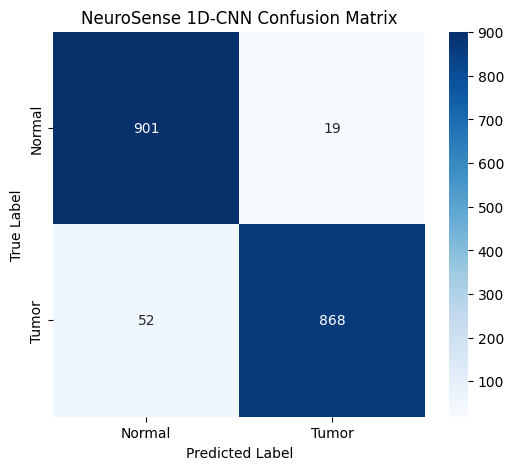

In [61]:
from sklearn.metrics import classification_report, confusion_matrix

# 1. Predict probabilities on the validation set
y_pred_probs = model.predict(X_val)
y_pred = (y_pred_probs > 0.5).astype("int32")

# 2. Print Classification Report (Precision, Recall, F1-Score)
print("Classification Report:")
print(classification_report(y_val, y_pred, target_names=["Normal", "Tumor/Anomaly Risk"]))

# 3. Generate Confusion Matrix
cm = confusion_matrix(y_val, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Normal", "Tumor"], yticklabels=["Normal", "Tumor"])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('NeuroSense 1D-CNN Confusion Matrix')
plt.show()

In [62]:
# 1. Convert EEG Model
eeg_model = tf.keras.models.load_model("models/neurosense_1d_best.keras")
converter_eeg = tf.lite.TFLiteConverter.from_keras_model(eeg_model)
converter_eeg.optimizations = [tf.lite.Optimize.DEFAULT]
with open("models/neurosense_eeg.tflite", "wb") as f:
    f.write(converter_eeg.convert())

Saved artifact at '/tmp/tmppftjz39e'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 178, 1), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  139726974095952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139726976419408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139726976431120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139726976431888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139726976432464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139726976434000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139726974095184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139726974096528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139726974093648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139726974091920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139726974094992: Ten